# EPD-GIT-5534 — TP 5 (corrigé officiel) — Séance 5 : Sécurité — détecter l'intrusion — Enseignante : Dr. Noulapeu Ngaffo Armielle

In [1]:
%matplotlib inline
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RNG = np.random.default_rng(5534)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| pandas", pd.__version__)


numpy 2.4.6 | pandas 3.0.6


## Étape B1 — Agréger les logs en sessions (machine, 10 min) (30 min)

Une session est la bonne granularité : ni l'événement (trop bruité), ni le
serveur-jour (trop grossier). 100 000 lignes → **10 000 sessions** (10 machines
× 1 008 fenêtres sur 7 jours). Attention au piège de la qualité des données :
compter bêtement les `auth_reussie = False` donne 4 828 « échecs » dont une
partie n'est pas des authentifications (rotations de logs, sauvegardes) —
**filtrer d'abord, compter ensuite**, et surveiller le volume de logs par
machine (un agent tombé = fenêtres vides = aveugle pendant l'attaque).

In [2]:
logs = pd.read_csv("data/nosys_logs.csv", parse_dates=["horodatage"])
print("lignes :", len(logs), "| machines :", logs.machine.nunique())
print("période :", logs.horodatage.min(), "->", logs.horodatage.max())
logs["echec"] = (~logs.auth_reussie.astype(bool)).astype(int)
logs["succes"] = 1 - logs.echec
logs["fenetre"] = logs.horodatage.dt.floor("10min")
print("lignes auth_reussie = False (comptage brut) :", logs.echec.sum(),
      f"≈ {logs.echec.sum() / 7:.0f}/jour")
print("message le plus fréquent en échec :")
print(logs.loc[logs.echec == 1, "message"].value_counts().head())

lignes : 100000 | machines : 10
période : 2026-10-01 00:00:00 -> 2026-10-07 22:39:54
lignes auth_reussie = False (comptage brut) : 4828 ≈ 690/jour
message le plus fréquent en échec :
message
Rotation des logs         697
Service sain              686
Sauvegarde terminee       672
Connexion SSH acceptee    657
Retry automatique         169
Name: count, dtype: int64


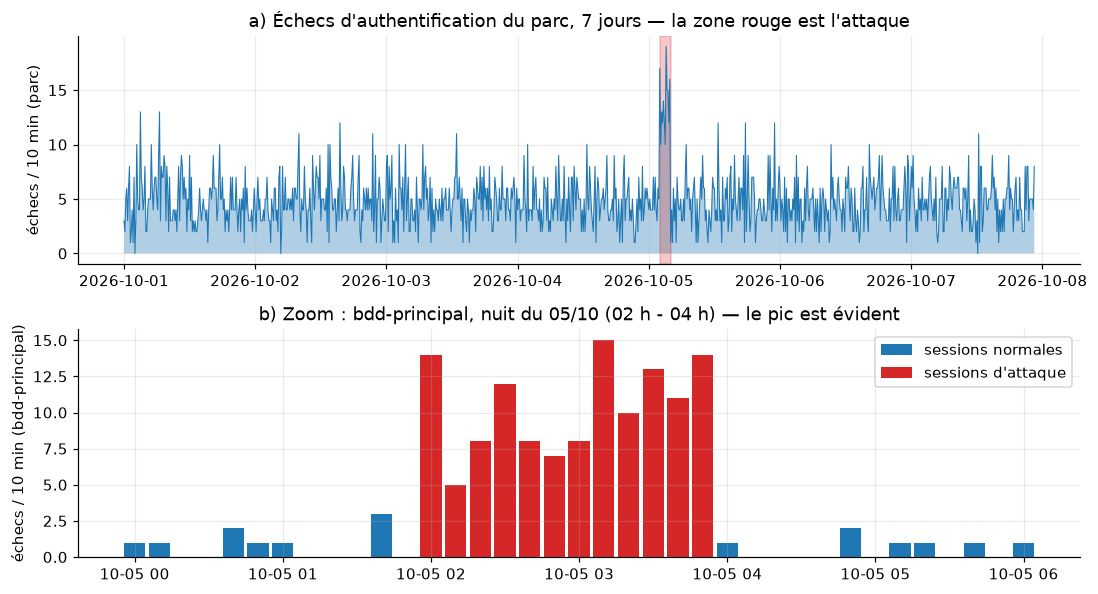

échecs pendant la fenêtre d'attaque : 125


In [3]:
# Échecs d'authentification du parc par fenêtre de 10 min, 7 jours
tot = logs.groupby("fenetre").echec.sum()
fig, ax = plt.subplots(2, 1, figsize=(10, 5.5))
ax[0].fill_between(tot.index, tot.values, alpha=.35, lw=0)
ax[0].plot(tot.index, tot.values, lw=.7)
t0, t1 = pd.Timestamp("2026-10-05 02:00"), pd.Timestamp("2026-10-05 04:00")
ax[0].axvspan(t0, t1, color="tab:red", alpha=.25)
ax[0].set_ylabel("échecs / 10 min (parc)")
ax[0].set_title("a) Échecs d'authentification du parc, 7 jours — la zone rouge est l'attaque")
# zoom bdd-principal, nuit du 05/10
z = logs[(logs.machine == "bdd-principal")
         & logs.fenetre.between(pd.Timestamp("2026-10-05 00:00"),
                                pd.Timestamp("2026-10-05 06:00"))]
z10 = z.groupby("fenetre").echec.sum()
att = (z10.index >= t0) & (z10.index < t1)
ax[1].bar(z10.index[~att], z10.values[~att], width=0.006, label="sessions normales")
ax[1].bar(z10.index[att], z10.values[att], width=0.006, color="tab:red",
          label="sessions d'attaque")
ax[1].set_ylabel("échecs / 10 min (bdd-principal)")
ax[1].set_title("b) Zoom : bdd-principal, nuit du 05/10 (02 h - 04 h) — le pic est évident")
ax[1].legend()
plt.tight_layout()
plt.show()
print("échecs pendant la fenêtre d'attaque :",
      logs.echec[logs.machine.eq("bdd-principal")
                 & logs.horodatage.between(t0, t1, inclusive="left")].sum())

## Étape B2 — Features d'attaque + entropie de Shannon (30 min)

Sept features par session : `echecs`, `taux_echec`, `echecs_consecutifs`
(rafale ininterrompue), `utilisateurs` (comptes testés en série),
`entropie` (diversité des comptes testés, en bits), `comptes_sensibles`
(échecs sur `root`, `admin`, `inconnu-*`), `nuit` (22 h - 06 h).
Entropie : $H = -\sum_i p_i \log_2 p_i$, où $p_i$ est la part des essais
portant sur le compte $i$.

In [4]:
from scipy.stats import entropy as shannon

# Vérification de l'entropie : à la main vs scipy, et cas connus
demo = np.array([1, 1])
p = demo / demo.sum()
print("à la main : %.4f bits | scipy : %.4f bits"
      % (float(-(p * np.log2(p)).sum()), shannon(demo, base=2)))
print("uniforme sur 8 comptes :", np.log2(8), "bits (attendu 3) ; un seul compte : 0 bit")

à la main : 1.0000 bits | scipy : 1.0000 bits
uniforme sur 8 comptes : 3.0 bits (attendu 3) ; un seul compte : 0 bit


In [5]:
SENSIBLES = {"root", "admin", "inconnu-1", "inconnu-2"}
g = logs.groupby(["machine", "fenetre"])
S = pd.DataFrame({
    "n_evenements": g.size(),
    "echecs": g["echec"].sum(),
    "succes": g["succes"].sum(),
    "utilisateurs": g["utilisateur"].nunique(),
    "comptes_sensibles": g.apply(
        lambda d: int(d.loc[d["echec"] == 1, "utilisateur"].isin(SENSIBLES).sum()),
        include_groups=False),
})
# Entropie de Shannon (base 2) des comptes testés dans la fenêtre
S["entropie"] = g["utilisateur"].apply(
    lambda u: float(shannon(list(pd.Series(list(u)).value_counts().values), base=2)))
# Rafale : plus longue séquence d'échecs consécutifs (ordre horodatage)
def max_run(d):
    e = d.sort_values("horodatage")["echec"].values
    best = cur = 0
    for v in e:
        cur = cur + 1 if v else 0
        best = max(best, cur)
    return best
S["echecs_consecutifs"] = g.apply(max_run, include_groups=False)
S["taux_echec"] = S["echecs"] / S["n_evenements"]
S["heure"] = S.index.get_level_values("fenetre").hour
S["nuit"] = ((S["heure"] < 6) | (S["heure"] >= 22)).astype(int)
S = S.reset_index()
print("sessions avec features :", S.shape, "(attendu : 10 000)")

# Étiquette (pour évaluer seulement) : la fenêtre d'attaque réelle
S["attaque"] = ((S.machine == "bdd-principal")
                & (S.fenetre >= pd.Timestamp("2026-10-05 02:00"))
                & (S.fenetre < pd.Timestamp("2026-10-05 04:00"))).astype(int)
att, base = S[S.attaque == 1], S[S.attaque == 0]
print("sessions d'attaque :", len(att), "soit %.2f %% des sessions"
      % (100 * len(att) / len(S)))
print(f"échecs/session  attaque : moy {att.echecs.mean():.1f}, max {att.echecs.max()} "
      f"| normale : max {base.echecs.max()}")
print(f"entropie  attaque : {att.entropie.mean():.2f} bits (max {att.entropie.max():.2f}) "
      f"| normale : {base.entropie.mean():.2f} bits")
print(f"utilisateurs attaque : {att.utilisateurs.mean():.1f} | succès pendant l'attaque : "
      f"{att.succes.sum()}")

sessions avec features : (10000, 12) (attendu : 10 000)
sessions d'attaque : 12 soit 0.12 % des sessions
échecs/session  attaque : moy 10.4, max 15 | normale : max 4
entropie  attaque : 1.73 bits (max 1.99) | normale : 2.22 bits
utilisateurs attaque : 3.7 | succès pendant l'attaque : 0


## Étape B3 — IsolationForest : isoler l'anormal, juger par le classement (40 min)

Non supervisé, `contamination=0.005` (a priori sur la fraction d'anomalies).
On juge le détecteur par son **classement** : précision@N, pas étiquette
binaire.

In [6]:
from sklearn.ensemble import IsolationForest

FEATS = ["echecs", "taux_echec", "utilisateurs", "entropie",
         "echecs_consecutifs", "comptes_sensibles", "nuit"]
X = S[FEATS].values
iso = IsolationForest(n_estimators=200, contamination=0.005,
                      random_state=5534, n_jobs=2)
iso.fit(X)
S["score_anomalie"] = -iso.decision_function(X)   # plus grand = plus anormal
S = S.sort_values("score_anomalie", ascending=False).reset_index(drop=True)
S["rang"] = np.arange(1, len(S) + 1)

print("rangs des 12 sessions d'attaque :",
      S.loc[S.attaque == 1, "rang"].tolist())
for n in (10, 30, 50):
    print(f"précision@{n} : {S.loc[:n - 1, 'attaque'].mean():.2f}")
print("rappel@30 :", S.loc[:29, "attaque"].sum() / S.attaque.sum())
print("par hasard, précision@30 serait : %.4f" % S.attaque.mean())

rangs des 12 sessions d'attaque : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
précision@10 : 1.00
précision@30 : 0.40
précision@50 : 0.24
rappel@30 : 1.0
par hasard, précision@30 serait : 0.0012


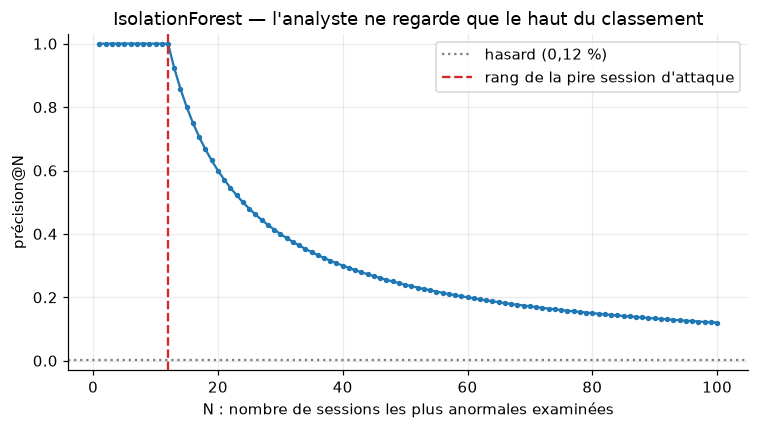

sessions d'attaque dans le top 30 : 12 | précision@30 = 0.40 | rappel@30 = 1.00


In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
prec_n = [S.loc[:n - 1, "attaque"].mean() for n in range(1, 101)]
ax.plot(range(1, 101), prec_n, marker="o", ms=2.5)
ax.axhline(S.attaque.mean(), color="0.5", ls=":", label="hasard (0,12 %)")
ax.axvline(S.loc[S.attaque == 1, "rang"].max(), color="tab:red", ls="--",
           label="rang de la pire session d'attaque")
ax.set_xlabel("N : nombre de sessions les plus anormales examinées")
ax.set_ylabel("précision@N")
ax.set_ylim(-0.03, 1.03)
ax.set_title("IsolationForest — l'analyste ne regarde que le haut du classement")
ax.legend()
plt.tight_layout()
plt.show()
n30 = int(S.loc[:29, "attaque"].sum())
print(f"sessions d'attaque dans le top 30 : {n30} | précision@30 = "
      f"{S.loc[:29, 'attaque'].mean():.2f} | rappel@30 = "
      f"{n30 / S.attaque.sum():.2f}")

**Lecture.** Les rangs 1 à 12 sont **exactement** les 12 sessions d'attaque
: précision@10 = 1,00, précision@30 = 0,40, rappel@30 = 1,00 — soit ≈ 333
fois mieux que le hasard. Au-delà du rang 12 remontent des sessions
« anormales mais normales » (défauts de service) : le classement est un
curseur, l'analyste descend jusqu'à ce que le coût de lecture dépasse la
valeur des alertes.

## Étape B4 — Le détecteur supervisé (30 min)

Les incidents passés sont des étiquettes : sessions de la fenêtre d'attaque =
1, les 9 988 autres = 0. Split **stratifié** 50/50, graine 5534, `class_weight`
équilibré — 6 positives en test.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score

X = S[FEATS].values          # S est trié par rang : X et étiquettes alignés
y = S["attaque"].values
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.5, stratify=y, random_state=5534)
print("positives en test :", yte.sum())
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=5534, n_jobs=2)
rf.fit(Xtr, ytr)
pred = rf.predict(Xte)
print(f"précision : {precision_score(yte, pred, zero_division=0):.2f} | "
      f"rappel : {recall_score(yte, pred):.2f}")

positives en test : 6


précision : 1.00 | rappel : 1.00


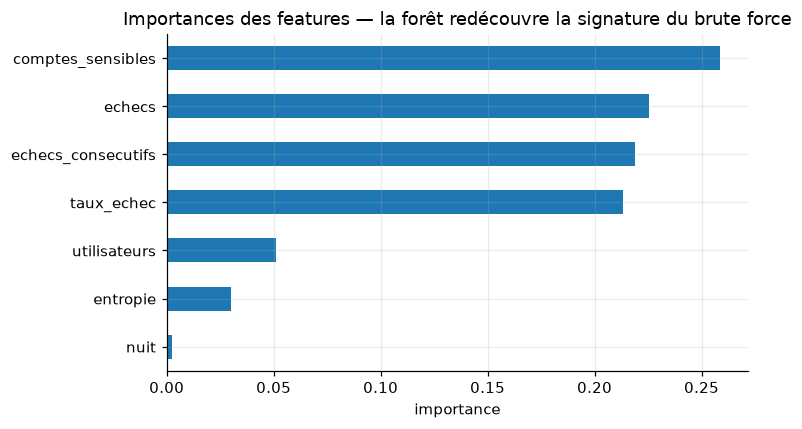

comptes_sensibles     0.259
echecs                0.226
echecs_consecutifs    0.219
taux_echec            0.213
utilisateurs          0.051
entropie              0.030
nuit                  0.002
dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values()
imp.plot.barh(ax=ax, color="tab:blue")
ax.set_title("Importances des features — la forêt redécouvre la signature du brute force")
ax.set_xlabel("importance")
plt.tight_layout()
plt.show()
print(imp.round(3).sort_values(ascending=False))

**Lecture.** Sur ce jeu, précision = rappel = 1,00 (6 positives en test) :
le signal est si net que la forêt sépare parfaitement — mais méfiez-vous du
100 % : l'intervalle de confiance sur 6 positives est énorme, et un modèle
parfait sur un jeu petit et propre échouera en production face à une attaque
différente. Les quatre features de tête (`comptes_sensibles`, `echecs`,
`echecs_consecutifs`, `taux_echec`) racontent la définition même d'un brute
force. Règles et modèle fonctionnent **en parallèle** : la règle (5 échecs /
10 min) couvre le cas trivial, le modèle couvre le reste.

## Étape B5 — Note d'incident (livrable, cellule markdown)

> **NOTE D'INCIDENT — INC-2026-1005-BDD**
>
> **Résumé** : campagne de brute force par authentification SSH contre
> `bdd-principal`, nuit du **05/10/2026, 02 h – 04 h** (12 sessions de 10 min
> consécutives, regroupées en un seul incident).
>
> **Faits mesurés** : **125 échecs d'authentification** en 2 h (≈ 10,4 échecs
> par session, jusqu'à 15 consécutifs), **zéro connexion réussie** pendant la
> fenêtre, 100 % des échecs portent sur des **comptes sensibles**
> (`root`, `admin`, `inconnu-1`, `inconnu-2`), entropie des comptes testés
> 1,73 bit contre 2,22 en normal (petite liste ordonnée, signature robotisée),
> exclusivement en fenêtre de nuit.
>
> **Détection** : remontée aux rangs 1–12 du classement IsolationForest
> (précision@10 = 1,0) et confirmée par la règle « 5 échecs / 10 min » —
> double canal, priorité maximale.
>
> **Action recommandée** : ① bloquer la source réseau à pare-feu et verrouiller
> les comptes `inconnu-*` ; ② imposer l'authentification par clé + fail2ban
> (bannissement après 5 échecs) sur `bdd-principal` ; ③ vérifier l'absence de
> succès ailleurs dans le parc (corrélation inter-machines) ; ④ journaliser
> l'incident comme étiquette neuve pour réentraîner le détecteur supervisé
> (boucle d'amélioration), en pseudonymisant les identités hors note
> d'incident (privacy by design).

**Livrable (à rendre)** : ① tableau des sessions avec features (B2), ②
classement top-30 avec précision@N (B3), ③ importances de la forêt supervisée
(B4), ④ la note d'incident ci-dessus (B5).